In [6]:
# ============================================================
# Simulation Study: Wasserstein Target Diagram
# Equal Sample Sizes
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

N = 1000

np.random.seed(123)

# --------------------------------------------------
# Observed data
# --------------------------------------------------

# Reference: Normal(5, 1.5^2), mean=5, SD=1.5
obs = np.random.normal(loc=5, scale=1.5, size=N)

# --------------------------------------------------
# Observed summary statistics
# --------------------------------------------------

std_obs = np.std(obs, ddof=0)
mean_obs = np.mean(obs)



# --------------------------------------------------
# Prediction distributions
# --------------------------------------------------

predictions = {
    # Same underlying distribution as reference: mean=5, SD=1.5
    "Pred 1: Normal(5,1.5^2)": np.random.normal(loc=5, scale=1.5, size=N),

    # Smaller mean and SD: mean=3, SD=1
    "Pred 2: Normal(3,1^2)": np.random.normal(loc=3, scale=1, size=N),

    # Larger mean and SD: mean=6, SD=2.5
    "Pred 3: Normal(6,2.5^2)": np.random.normal(loc=6, scale=2.5, size=N),

    # Larger mean, smaller SD: mean=6, SD=1
    "Pred 4: Normal(6,1^2)": np.random.normal(loc=6, scale=1, size=N),

    # Smaller mean, larger SD: mean=3, SD=2.5
    "Pred 5: Normal(3,2.5^2)": np.random.normal(loc=3, scale=2.5, size=N),

    # Smaller mean, same SD: mean=4, SD=1.5
    "Pred 6: Normal(4,1.5^2)": np.random.normal(loc=4, scale=1.5, size=N),
}




# --------------------------------------------------
# Common quantile grid
# --------------------------------------------------

#N = 1000
u = (np.arange(1, N + 1) - 0.5) / N

obs_q = np.sort(obs)


# --------------------------------------------------
# Compute Wasserstein target diagram quantities
# --------------------------------------------------

Model = []
Mean = []
Std = []
Centered_W2 = []
Signed_Centered_W2 = []
Bias = []
W_2 = []
#Quantile_Corr = []


for name, pred in predictions.items():

    pred_q = np.sort(pred)

    # Means and standard deviations
    mean_pred = np.mean(pred)
    std_pred = np.std(pred, ddof=0)

    # Center the quantile functions
    obs_q_centered = obs_q - np.mean(obs_q)
    pred_q_centered = pred_q - np.mean(pred_q)

    # Centered W2 distance
    w2_centered = np.sqrt(
        np.mean((obs_q_centered - pred_q_centered) ** 2)
    )

    # Sign determined by difference in standard deviations
    signed_w2_centered = (
        np.sign(std_pred - std_obs) * w2_centered
    )

    # Mean bias
    bias = mean_pred - mean_obs

    # Total W2 distance
    w2 = np.sqrt(
        w2_centered**2 + bias**2
    )

    # Quantile correlation
    #rho_q = np.corrcoef(obs_q, pred_q)[0, 1]

    # Save results
    Model.append(name)
    Mean.append(mean_pred)
    Std.append(std_pred)
    Centered_W2.append(w2_centered)
    Signed_Centered_W2.append(signed_w2_centered)
    Bias.append(bias)
    W_2.append(w2)
    #Quantile_Corr.append(rho_q)


# ============================================================
# Summarize and save simulation results
# ============================================================

# Short model names for table and figure
Model_short = ["Prediction 1", "Prediction 2", "Prediction 3", "Prediction 4", "Prediction 5", "Prediction 6"]

# Create results table
results = pd.DataFrame({
    "Model": Model_short,
    "prediction_std": Std,
    "ground_truth_std": std_obs,
    "Signed_Centered_W_2": Signed_Centered_W2,
    "prediction_mean": Mean,
    "ground_truth_mean": mean_obs,
    "Bias": Bias,
    "W_2": W_2
})

# Save results
results.to_csv(
    "/content/sample_data/Simulation_Sample_Equal_Length_Wasserstein_Target_Diagram.csv",
    index=False
)

# Print results with six decimal places
print(f"Observed length = {len(obs)}")
print(f"Observed mean   = {mean_obs:.6f}")
print(f"Observed std    = {std_obs:.6f}")

print(results.to_string(index=False, float_format=lambda x: f"{x:.6f}"))


Observed length = 1000
Observed mean   = 4.940654
Observed std    = 1.501181
       Model  prediction_std  ground_truth_std  Signed_Centered_W_2  prediction_mean  ground_truth_mean      Bias      W_2
Prediction 1        1.437014          1.501181            -0.108362         5.012584           4.940654  0.071930 0.130062
Prediction 2        0.981458          1.501181            -0.524072         3.010353           4.940654 -1.930301 2.000178
Prediction 3        2.472612          1.501181             0.979372         6.166197           4.940654  1.225543 1.568797
Prediction 4        1.005029          1.501181            -0.502205         6.059758           4.940654  1.119104 1.226623
Prediction 5        2.442828          1.501181             0.949636         2.953840           4.940654 -1.986814 2.202099
Prediction 6        1.494127          1.501181            -0.082435         4.043527           4.940654 -0.897127 0.900907


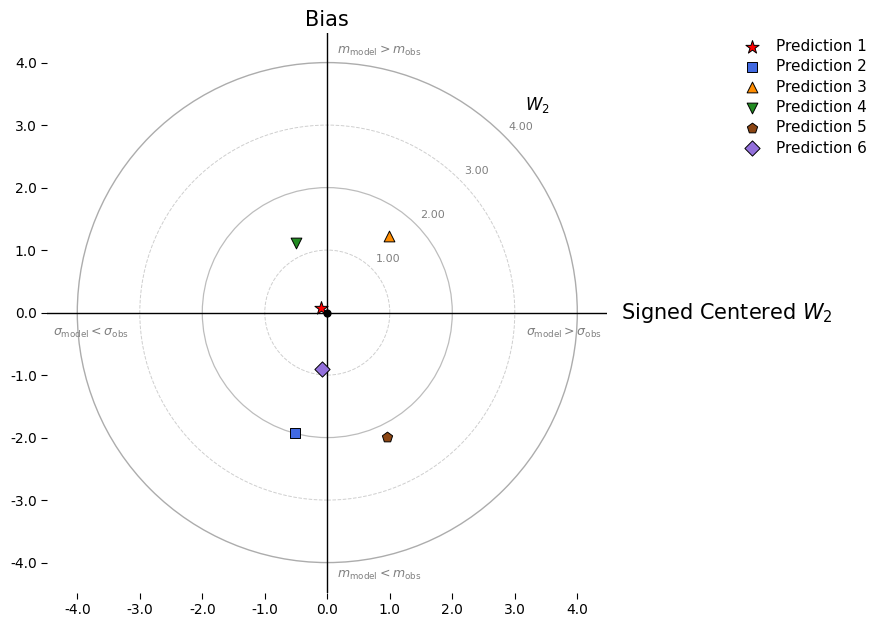

In [7]:
# ============================================================
# Wasserstein Target Diagram
# ============================================================

fig, ax = plt.subplots(figsize=(8, 8))


# ------------------------------------------------------------
# Determine outer W2 radius
# Always use exactly four circles
# ------------------------------------------------------------

max_w2 = np.max(W_2)

if max_w2 <= 0.1:
    outer_step = 0.05
elif max_w2 <= 0.2:
    outer_step = 0.10
elif max_w2 <= 0.5:
    outer_step = 0.20
elif max_w2 <= 1.0:
    outer_step = 0.40
elif max_w2 <= 2.0:
    outer_step = 0.80
elif max_w2 <= 5.0:
    outer_step = 2.0
elif max_w2 <= 10.0:
    outer_step = 4.0
else:
    outer_step = 4.0

rmax = np.ceil(max_w2 / outer_step) * outer_step

# Exactly four equally spaced circles
radii = np.array([rmax / 4, rmax / 2, 3 * rmax / 4, rmax])


# ------------------------------------------------------------
# Draw exactly four W2 circles
# 1st dashed, 2nd solid, 3rd dashed, 4th solid
# ------------------------------------------------------------

circle_styles = [
    ("--", 0.7, 0.38),
    ("-", 0.9, 0.52),
    ("--", 0.7, 0.38),
    ("-", 1.0, 0.65)
]

for r, (linestyle, linewidth, alpha) in zip(radii, circle_styles):
    circle = plt.Circle((0, 0), r, fill=False, edgecolor="gray",
                        linewidth=linewidth, linestyle=linestyle,
                        alpha=alpha, zorder=0)
    ax.add_patch(circle)


# ------------------------------------------------------------
# Label W2 contours
# Label second and outer circles only
# ------------------------------------------------------------

theta = np.pi / 4

for i in [0,1,2,3]:
    r = radii[i]
    ax.text((r + 0.025 * rmax) * np.cos(theta),
            (r + 0.025 * rmax) * np.sin(theta),
            f"{r:.2f}", fontsize=8, color="gray",
            ha="left", va="bottom")


# ------------------------------------------------------------
# W2 label
# ------------------------------------------------------------

ax.text((rmax * 1.12) * np.cos(theta),
        (rmax * 1.12) * np.sin(theta),
        r"$W_2$", fontsize=12, color="black",
        ha="left", va="bottom")


# ------------------------------------------------------------
# Model colors and markers
# ------------------------------------------------------------


# Highlight the correctly specified model in red
model_colors = {
    "Prediction 1": "red",
    "Prediction 2": "royalblue",
    "Prediction 3": "darkorange",
    "Prediction 4": "forestgreen",
    "Prediction 5": "saddlebrown",
    "Prediction 6": "mediumpurple"
}

model_markers = {
    "Prediction 1": "*",
    "Prediction 2": "s",
    "Prediction 3": "^",
    "Prediction 4": "v",
    "Prediction 5": "p",
    "Prediction 6": "D"
}



# ------------------------------------------------------------
# Plot models
# ------------------------------------------------------------

for x, y, name in zip(
    Signed_Centered_W2,
    Bias,
    Model_short
):

    color = model_colors[name]
    marker = model_markers[name]

    # Highlight the same-distribution prediction
    if name == "Prediction 1":
        size = 100
        linewidth = 0.7
    else:
        size = 60
        linewidth = 0.7

    ax.scatter(
        x,
        y,
        s=size,
        marker=marker,
        facecolor=color,
        edgecolor="black",
        linewidth=linewidth,
        label=name,
        zorder=3
    )


# ------------------------------------------------------------
# Reference coordinate axes
# ------------------------------------------------------------

ax.axhline(
    0,
    color="black",
    linewidth=1.0,
    zorder=1
)

ax.axvline(
    0,
    color="black",
    linewidth=1.0,
    zorder=1
)


# ------------------------------------------------------------
# Perfect-fit target
# ------------------------------------------------------------

# Origin represents perfect agreement
ax.scatter(
    0,
    0,
    s=24,
    color="black",
    zorder=4
)


# ------------------------------------------------------------
# Axis limits and aspect ratio
# ------------------------------------------------------------

limit = rmax * 1.12

ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)

# Equal scaling preserves circular W2 contours
ax.set_aspect(
    "equal",
    adjustable="box"
)


# ------------------------------------------------------------
# Remove conventional outer box and axis labels
# ------------------------------------------------------------

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel("")
ax.set_ylabel("")


# ------------------------------------------------------------
# Coordinate titles
# ------------------------------------------------------------

# Horizontal coordinate title
ax.text(
    limit * 1.05,
    0,
    r"Signed Centered $W_2$",
    fontsize=15,
    ha="left",
    va="center",
    clip_on=False
)

# Vertical coordinate title
ax.text(
    0,
    limit * 1.01,
    "Bias",
    fontsize=15,
    ha="center",
    va="bottom",
    clip_on=False
)


# ------------------------------------------------------------
# Interpretation of coordinate signs
# ------------------------------------------------------------

# Smaller model standard deviation
ax.text(
    -limit * 0.98,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}<\sigma_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="top"
)

# Larger model standard deviation
ax.text(
    limit * 0.98,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}>\sigma_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="right",
    va="top"
)

# Larger model mean
ax.text(
    0.035 * limit,
    limit * 0.96,
    r"$m_{\mathrm{model}}>m_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="top"
)

# Smaller model mean
ax.text(
    0.035 * limit,
    -limit * 0.96,
    r"$m_{\mathrm{model}}<m_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="bottom"
)


# ------------------------------------------------------------
# Model legend
# ------------------------------------------------------------

ax.legend(
    frameon=False,
    fontsize=11,
    loc="upper left",
    bbox_to_anchor=(1.22, 1.00),
    handletextpad=0.6,
    labelspacing=0.35,
    borderaxespad=0
)



# ------------------------------------------------------------
# Tick locations: four ticks on each side of each axis
# ------------------------------------------------------------

ticks = np.linspace(-rmax, rmax, 9)

ax.set_xticks(ticks)
ax.set_yticks(ticks)

# Adaptive number formatting
from matplotlib.ticker import FormatStrFormatter

if rmax < 1:
    tick_format = "%.2f"
elif rmax < 10:
    tick_format = "%.1f"
else:
    tick_format = "%.0f"

ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))

ax.tick_params(direction="out", labelsize=10, length=4)



# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.08,
    right=0.78,
    bottom=0.08,
    top=0.97
)


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "/content/sample_data/Simulation_Sample_Equal_Length_Wasserstein_Target_Diagram.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# =================================================================
# Conventional Target Diagram: Distribution Simulation Equal Length
# =================================================================


Mean = []
Std = []
Bias = []
CRMSE = []
Signed_CRMSE = []
RMSE = []

for name, pred in predictions.items():

    assert len(pred) == len(obs), f"Unequal sample sizes for {name}"

    mean_pred = np.mean(pred)
    std_pred = np.std(pred, ddof=0)

    # Mean bias
    bias = mean_pred - mean_obs

    # Centered RMSE
    # Pairing across simulation replicates is retained
    crmse = np.sqrt(np.mean(((pred - mean_pred) - (obs - mean_obs))**2))

    # Signed centered RMSE
    signed_crmse = np.sign(std_pred - std_obs) * crmse

    # RMSE
    rmse = np.sqrt(np.mean((pred - obs)**2))

    # Check conventional target decomposition
    # RMSE^2 = Bias^2 + CRMSE^2
    assert np.isclose(rmse**2, bias**2 + crmse**2, rtol=1e-8, atol=1e-10)

    Mean.append(mean_pred)
    Std.append(std_pred)
    Bias.append(bias)
    CRMSE.append(crmse)
    Signed_CRMSE.append(signed_crmse)
    RMSE.append(rmse)

Mean = np.array(Mean)
Std = np.array(Std)
Bias = np.array(Bias)
CRMSE = np.array(CRMSE)
Signed_CRMSE = np.array(Signed_CRMSE)
RMSE = np.array(RMSE)


# ========================================================
# Summarize results
# ========================================================

Model_short = ["Prediction 1", "Prediction 2", "Prediction 3", "Prediction 4", "Prediction 5", "Prediction 6"]

results_target = pd.DataFrame({
    "Model": Model_short,
    "prediction_std": Std,
    "ground_truth_std": std_obs,
    "Signed_CRMSE": Signed_CRMSE,
    "prediction_mean": Mean,
    "ground_truth_mean": mean_obs,
    "Bias": Bias,
    "RMSE": RMSE
})


# Save results
results_target.to_csv(
    "/content/sample_data/Simulation_Sample_Equal_Length_Target_Diagram.csv",
    index=False
)

# Print results with six decimal places
print(results_target.to_string(index=False, float_format=lambda x: f"{x:.6f}"))



       Model  prediction_std  ground_truth_std  Signed_CRMSE  prediction_mean  ground_truth_mean      Bias     RMSE
Prediction 1        1.437014          1.501181     -2.110338         5.012584           4.940654  0.071930 2.111563
Prediction 2        0.981458          1.501181     -1.819974         3.010353           4.940654 -1.930301 2.652992
Prediction 3        2.472612          1.501181      2.927675         6.166197           4.940654  1.225543 3.173837
Prediction 4        1.005029          1.501181     -1.801136         6.059758           4.940654  1.119104 2.120491
Prediction 5        2.442828          1.501181      2.864732         2.953840           4.940654 -1.986814 3.486276
Prediction 6        1.494127          1.501181     -2.067881         4.043527           4.940654 -0.897127 2.254100


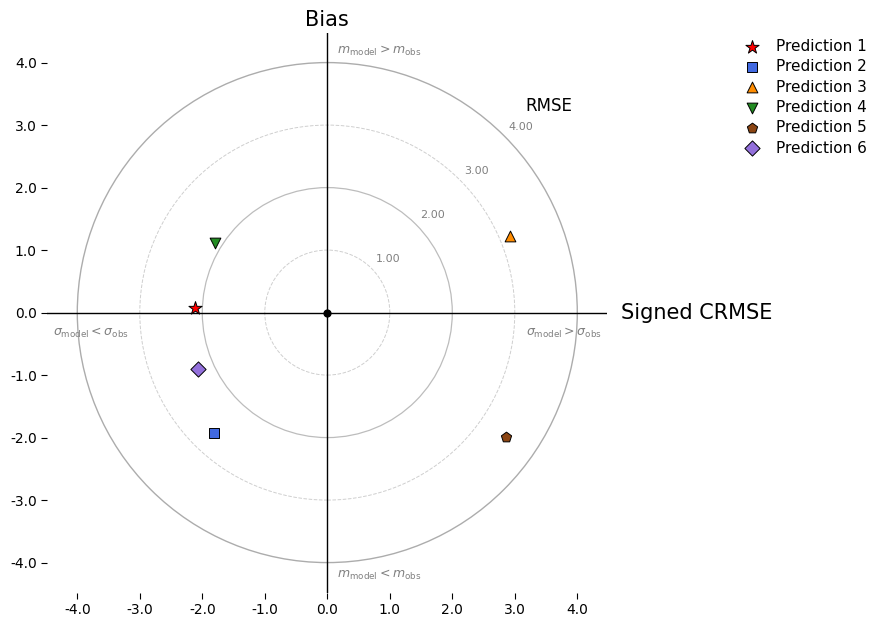

In [10]:
# ============================================================
# Target Diagram
# ============================================================

fig, ax = plt.subplots(figsize=(8, 8))


# ------------------------------------------------------------
# Determine outer RMSE radius
# Always use exactly four circles
# ------------------------------------------------------------

max_RMSE = np.max(RMSE)

if max_RMSE <= 0.1:
    outer_step = 0.05
elif max_RMSE <= 0.2:
    outer_step = 0.10
elif max_RMSE <= 0.5:
    outer_step = 0.20
elif max_RMSE <= 1.0:
    outer_step = 0.40
elif max_RMSE <= 2.0:
    outer_step = 0.80
elif max_RMSE <= 5.0:
    outer_step = 2.0
elif max_RMSE <= 10.0:
    outer_step = 4.0
else:
    outer_step = 4.0

rmax = np.ceil(max_RMSE / outer_step) * outer_step

# Exactly four equally spaced circles
radii = np.array([rmax / 4, rmax / 2, 3 * rmax / 4, rmax])


# ------------------------------------------------------------
# Draw exactly four RMSE circles
# 1st dashed, 2nd solid, 3rd dashed, 4th solid
# ------------------------------------------------------------

circle_styles = [
    ("--", 0.7, 0.38),
    ("-", 0.9, 0.52),
    ("--", 0.7, 0.38),
    ("-", 1.0, 0.65)
]

for r, (linestyle, linewidth, alpha) in zip(radii, circle_styles):
    circle = plt.Circle((0, 0), r, fill=False, edgecolor="gray",
                        linewidth=linewidth, linestyle=linestyle,
                        alpha=alpha, zorder=0)
    ax.add_patch(circle)


# ------------------------------------------------------------
# Label RMSE contours
# Label second and outer circles only
# ------------------------------------------------------------

theta = np.pi / 4

for i in [0,1,2,3]:
    r = radii[i]
    ax.text((r + 0.025 * rmax) * np.cos(theta),
            (r + 0.025 * rmax) * np.sin(theta),
            f"{r:.2f}", fontsize=8, color="gray",
            ha="left", va="bottom")


# ------------------------------------------------------------
# RMSE label
# ------------------------------------------------------------

ax.text((rmax * 1.12) * np.cos(theta),
        (rmax * 1.12) * np.sin(theta),
        r"RMSE", fontsize=12, color="black",
        ha="left", va="bottom")


# ------------------------------------------------------------
# Model colors and markers
# ------------------------------------------------------------


# Highlight the correctly specified model in red
model_colors = {
    "Prediction 1": "red",
    "Prediction 2": "royalblue",
    "Prediction 3": "darkorange",
    "Prediction 4": "forestgreen",
    "Prediction 5": "saddlebrown",
    "Prediction 6": "mediumpurple",
}

model_markers = {
    "Prediction 1": "*",
    "Prediction 2": "s",
    "Prediction 3": "^",
    "Prediction 4": "v",
    "Prediction 5": "p",
    "Prediction 6": "D",
}



# ------------------------------------------------------------
# Plot models
# ------------------------------------------------------------

for x, y, name in zip(
    Signed_CRMSE,
    Bias,
    Model_short
):

    color = model_colors[name]
    marker = model_markers[name]

    # Highlight the same-distribution prediction
    if name == "Prediction 1":
        size = 100
        linewidth = 0.7
    else:
        size = 60
        linewidth = 0.7

    ax.scatter(
        x,
        y,
        s=size,
        marker=marker,
        facecolor=color,
        edgecolor="black",
        linewidth=linewidth,
        label=name,
        zorder=3
    )


# ------------------------------------------------------------
# Reference coordinate axes
# ------------------------------------------------------------

ax.axhline(
    0,
    color="black",
    linewidth=1.0,
    zorder=1
)

ax.axvline(
    0,
    color="black",
    linewidth=1.0,
    zorder=1
)


# ------------------------------------------------------------
# Perfect-fit target
# ------------------------------------------------------------

# Origin represents perfect agreement
ax.scatter(
    0,
    0,
    s=24,
    color="black",
    zorder=4
)


# ------------------------------------------------------------
# Axis limits and aspect ratio
# ------------------------------------------------------------

limit = rmax * 1.12

ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)

# Equal scaling preserves circular RMSE contours
ax.set_aspect(
    "equal",
    adjustable="box"
)


# ------------------------------------------------------------
# Remove conventional outer box and axis labels
# ------------------------------------------------------------

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel("")
ax.set_ylabel("")


# ------------------------------------------------------------
# Coordinate titles
# ------------------------------------------------------------

# Horizontal coordinate title
ax.text(
    limit * 1.05,
    0,
    r"Signed CRMSE",
    fontsize=15,
    ha="left",
    va="center",
    clip_on=False
)

# Vertical coordinate title
ax.text(
    0,
    limit * 1.01,
    "Bias",
    fontsize=15,
    ha="center",
    va="bottom",
    clip_on=False
)


# ------------------------------------------------------------
# Interpretation of coordinate signs
# ------------------------------------------------------------

# Smaller model standard deviation
ax.text(
    -limit * 0.98,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}<\sigma_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="top"
)

# Larger model standard deviation
ax.text(
    limit * 0.98,
    -0.045 * limit,
    r"$\sigma_{\mathrm{model}}>\sigma_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="right",
    va="top"
)

# Larger model mean
ax.text(
    0.035 * limit,
    limit * 0.96,
    r"$m_{\mathrm{model}}>m_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="top"
)

# Smaller model mean
ax.text(
    0.035 * limit,
    -limit * 0.96,
    r"$m_{\mathrm{model}}<m_{\mathrm{obs}}$",
    fontsize=9,
    color="gray",
    ha="left",
    va="bottom"
)


# ------------------------------------------------------------
# Model legend
# ------------------------------------------------------------

ax.legend(
    frameon=False,
    fontsize=11,
    loc="upper left",
    bbox_to_anchor=(1.22, 1.00),
    handletextpad=0.6,
    labelspacing=0.35,
    borderaxespad=0
)



# ------------------------------------------------------------
# Tick locations: four ticks on each side of each axis
# ------------------------------------------------------------

ticks = np.linspace(-rmax, rmax, 9)

ax.set_xticks(ticks)
ax.set_yticks(ticks)

# Adaptive number formatting
from matplotlib.ticker import FormatStrFormatter

if rmax < 1:
    tick_format = "%.2f"
elif rmax < 10:
    tick_format = "%.1f"
else:
    tick_format = "%.0f"

ax.xaxis.set_major_formatter(FormatStrFormatter(tick_format))
ax.yaxis.set_major_formatter(FormatStrFormatter(tick_format))

ax.tick_params(direction="out", labelsize=10, length=4)



# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.08,
    right=0.78,
    bottom=0.08,
    top=0.97
)


# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "/content/sample_data/Simulation_Sample_Equal_Length_Target_Diagram.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()